# Feature Selection using Hierarchical Clustering #

This follows a tutorial from: https://www.youtube.com/watch?v=oymY1Iqollo
<br>
This tutorial uses the Credit Score data set.  

In [2]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd 

import matplotlib.pyplot as plt
import seaborn as sns

## Hierarchical Clustering

In [4]:
# Load Data
credit_score = pd.read_csv('data/credit_score.csv')

# Select features
df_features = credit_score.drop(['CUST_ID', 'CAT_GAMBLING', 'CAT_DEBT', 'CAT_CREDIT_CARD', 'CAT_MORTGAGE', 'CAT_SAVINGS_ACCOUNT', 'CAT_DEPENDENTS', 'CREDIT_SCORE', 'DEFAULT'], axis=1)

#Standardize the features
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_features)
df_scaled = pd.DataFrame(df_scaled, columns=df_features.columns)

In [5]:
#Transpose so that each row is a feature
df_transposed = df_scaled.transpose()

np.shape(df_transposed) 

(78, 1000)

In [8]:
# Perform hierarchical clustering on features
linked = linkage(df_transposed, method='ward', metric='euclidean')

np.shape(linked)

(77, 4)

In [9]:
df_linked = pd.DataFrame(linked, columns=['c1', 'c2', 'distance', 'size'])
df_linked[['c1', 'c2', 'size']] = df_linked[['c1', 'c2', 'size']].astype(int)

df_linked.head(10)

,c1,c2,distance,size
0,48,49,0.001115,2
1,12,13,0.110213,2
2,66,67,0.140091,2
3,54,55,2.917148,2
4,30,31,3.256809,2
5,36,37,4.094988,2
6,0,72,5.368175,2
7,18,19,5.881761,2
8,73,84,8.531166,3
9,41,71,9.644045,2


## Visualizing the Clusters

Text(0, 0.5, "Ward's Distance")

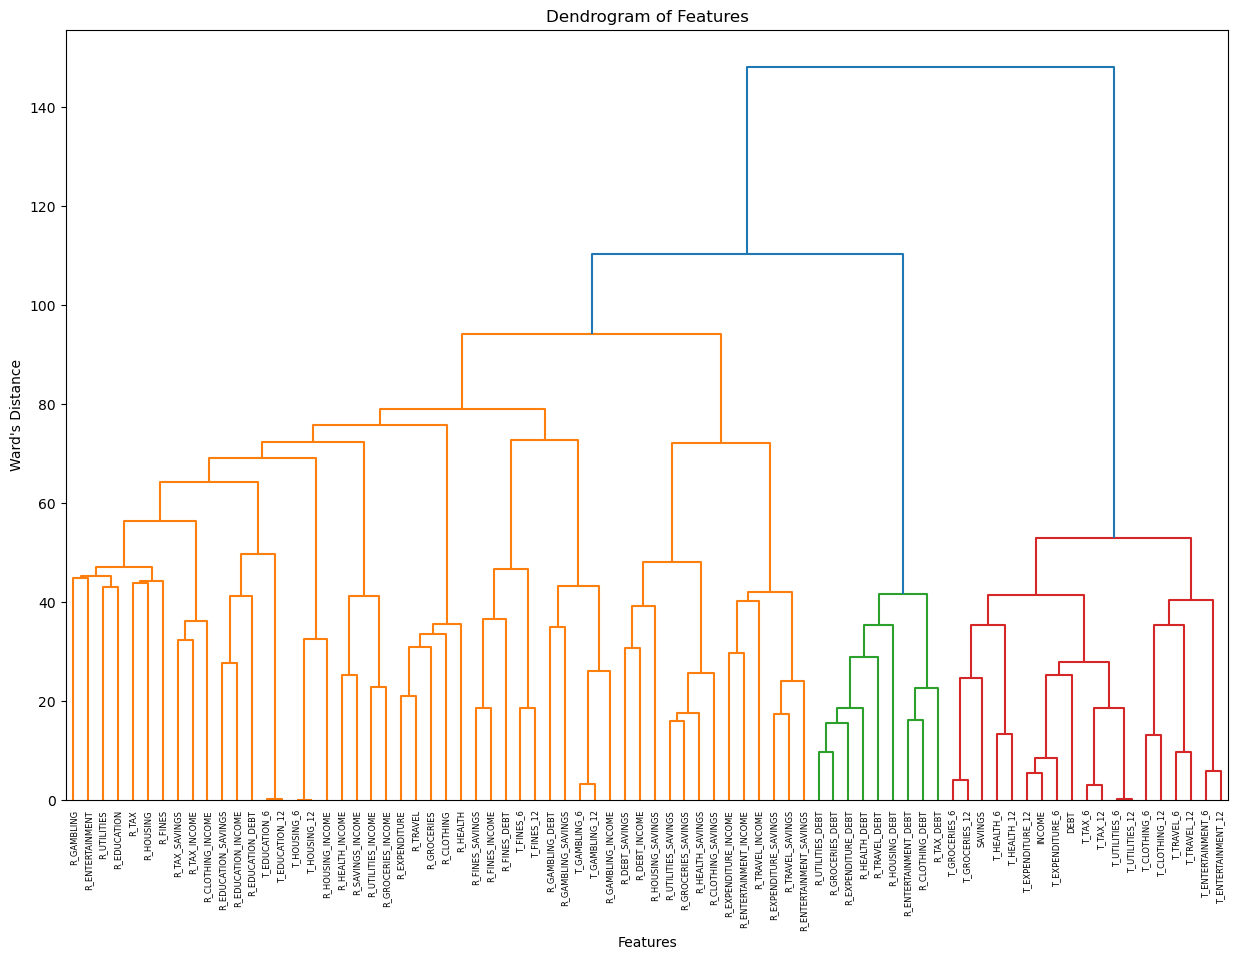

In [10]:
# Create a dendrogram to visualize the feature clustering
plt.figure(figsize=(15, 10))
dendrogram(linked, labels=df_features.columns, orientation='top', distance_sort='descending', show_leaf_counts=True)

plt.title('Dendrogram of Features')
plt.xlabel('Features')
plt.ylabel('Ward\'s Distance')

## Group the Features into Clusters

In [11]:
num_clusters = 10 # Set the number of clusters
labels = fcluster(linked, num_clusters, criterion='maxclust')
  

In [13]:
# Find correlation between features and credit score
correlations=[]
for col in df_features.columns:
    corr = credit_score['CREDIT_SCORE'].corr(df_features[col])
    corr = round(corr, 3)
    correlations.append(corr)

In [16]:
df_clusters = pd.DataFrame(list(zip(df_features.columns, labels, correlations)), columns=['Feature', 'Cluster', 'Correlation'])

df_clusters['abs_corr'] = df_clusters['Correlation'].abs()
df_clusters.sort_values(by=['Cluster','abs_corr'], ascending=[True,False], inplace=True)

df_clusters.reset_index(drop=True, inplace=True)
df_clusters.head(10)

,Feature,Cluster,Correlation,abs_corr
0,DEBT,1,-0.327,0.327
1,T_ENTERTAINMENT_12,1,0.109,0.109
2,T_ENTERTAINMENT_6,1,0.084,0.084
3,T_GROCERIES_6,1,-0.081,0.081
4,SAVINGS,1,0.079,0.079
5,T_GROCERIES_12,1,-0.073,0.073
6,T_HEALTH_12,1,0.057,0.057
7,T_TAX_12,1,0.038,0.038
8,T_TAX_6,1,0.036,0.036
9,INCOME,1,0.029,0.029


In [ ]:
# Count the number of features in each of the Clusters
df_clusters['Cluster'].value_counts()

Cluster
1     19
10    15
2      9
4      7
3      6
5      5
6      5
7      5
8      4
9      3
Name: count, dtype: int64

## Sense Check the Clusters

In [19]:
c2_features = df_clusters[df_clusters['Cluster']==2]['Feature'].tolist()
c3_features = df_clusters[df_clusters['Cluster']==3]['Feature'].tolist()

print(c2_features)
print(c3_features)  

['R_EXPENDITURE_DEBT', 'R_UTILITIES_DEBT', 'R_GROCERIES_DEBT', 'R_TAX_DEBT', 'R_ENTERTAINMENT_DEBT', 'R_HEALTH_DEBT', 'R_CLOTHING_DEBT', 'R_TRAVEL_DEBT', 'R_HOUSING_DEBT']
['R_ENTERTAINMENT_INCOME', 'R_ENTERTAINMENT_SAVINGS', 'R_EXPENDITURE_SAVINGS', 'R_EXPENDITURE_INCOME', 'R_TRAVEL_SAVINGS', 'R_TRAVEL_INCOME']


Text(0.5, 1.0, 'Correlation Heatmap for Cluster 2 Features')

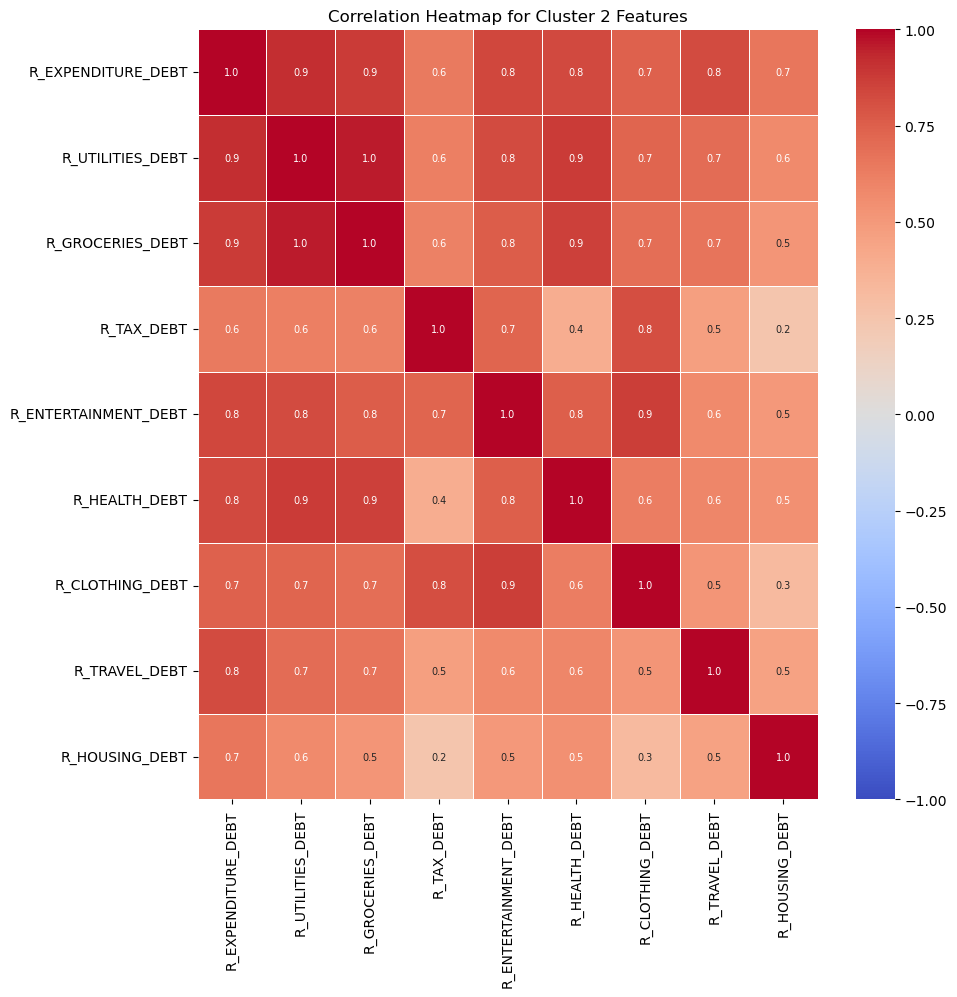

In [20]:
# Plot correlations for features in cluster 2
corr = credit_score[c2_features].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5, fmt=".1f", annot_kws={"size": 7}, vmin=-1, vmax=1)
plt.title('Correlation Heatmap for Cluster 2 Features')

Text(0.5, 1.0, 'Correlation Heatmap for Cluster 3 Features')

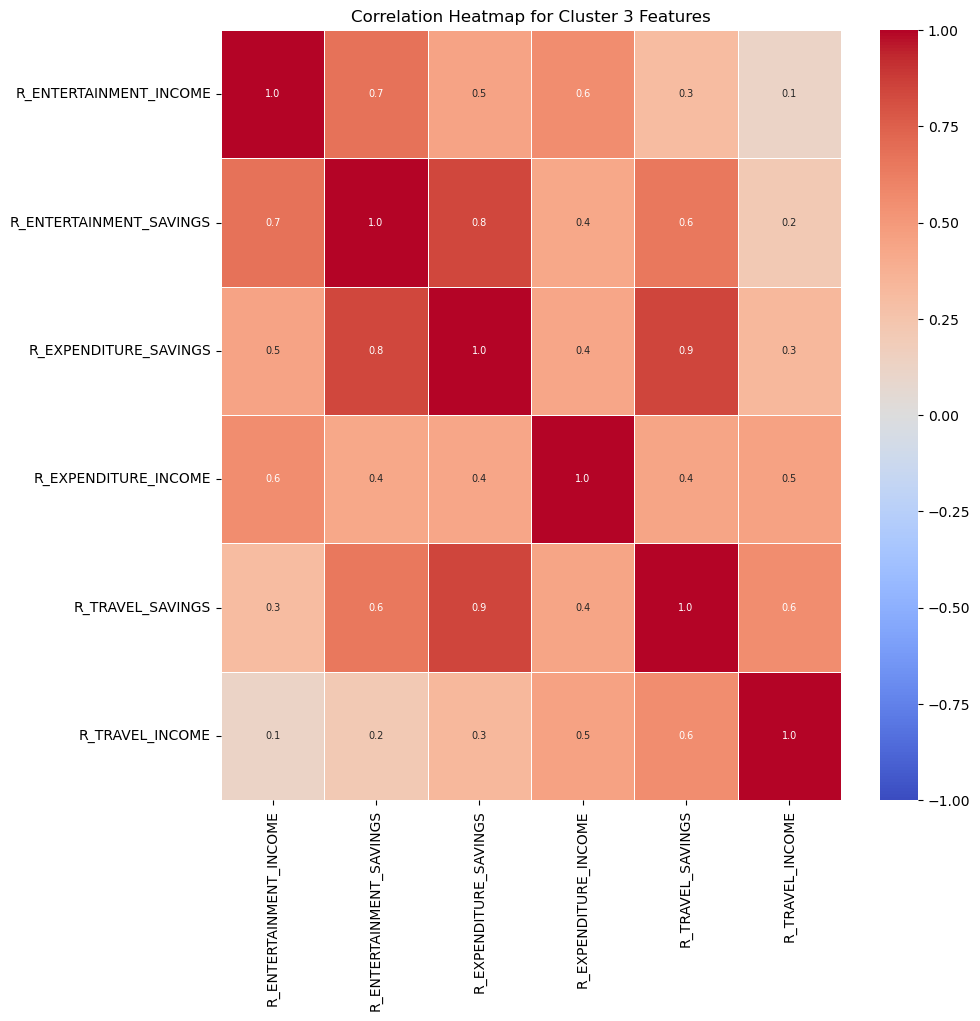

In [21]:
# Plot correlations for features in cluster 3
corr = credit_score[c3_features].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5, fmt=".1f", annot_kws={"size": 7}, vmin=-1, vmax=1)
plt.title('Correlation Heatmap for Cluster 3 Features')

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5]),
 [Text(0, 0.5, 'R_EXPENDITURE_DEBT'),
  Text(0, 1.5, 'R_UTILITIES_DEBT'),
  Text(0, 2.5, 'R_GROCERIES_DEBT'),
  Text(0, 3.5, 'R_TAX_DEBT'),
  Text(0, 4.5, 'R_ENTERTAINMENT_DEBT'),
  Text(0, 5.5, 'R_HEALTH_DEBT'),
  Text(0, 6.5, 'R_CLOTHING_DEBT'),
  Text(0, 7.5, 'R_TRAVEL_DEBT'),
  Text(0, 8.5, 'R_HOUSING_DEBT'),
  Text(0, 9.5, 'R_ENTERTAINMENT_INCOME'),
  Text(0, 10.5, 'R_ENTERTAINMENT_SAVINGS'),
  Text(0, 11.5, 'R_EXPENDITURE_SAVINGS'),
  Text(0, 12.5, 'R_EXPENDITURE_INCOME'),
  Text(0, 13.5, 'R_TRAVEL_SAVINGS'),
  Text(0, 14.5, 'R_TRAVEL_INCOME')])

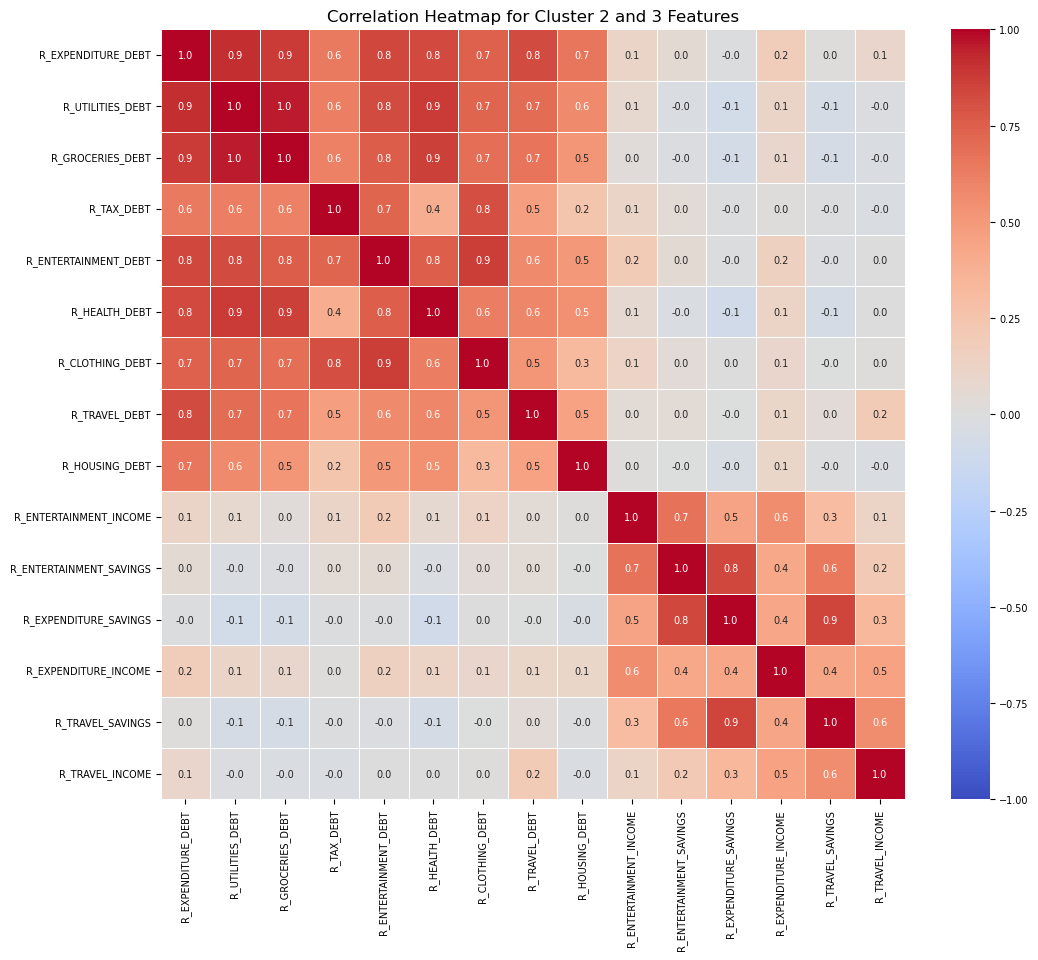

In [23]:
# Plot correlations for features in cluster 2 and 3
corr = df_features[np.append(c2_features, c3_features)].corr()

#plot correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5, fmt=".1f", annot_kws={"size": 7}, vmin=-1, vmax=1)
plt.title('Correlation Heatmap for Cluster 2 and 3 Features')

#change the size of colorbar labels
cbar = plt.gcf().axes[-1]
cbar.tick_params(labelsize=7)
plt.xticks(size=7)
plt.yticks(size=7)

This process is similar to Principal Component Analysis, but this is far more explainable.  PCA pulls together features, but makes them unexplainable because principal components are jumbles of the 